# Regular 1

| | |
|---|---|
| Thời gian | 90 phút |
| Hình thức | Làm trực tiếp trên notebook này. Không xóa đề. |

### Rules
1. Import các thư viện đã học.
2. Mọi nhận xét viết ngắn gọn, dựa trên kết quả vừa tính — không copy insight có sẵn.
3. Chạy cell theo thứ tự từ trên xuống.
4. Biểu đồ phải có title và nhãn trục. In kết quả số ra màn hình.

### Bảng điểm tóm tắt

| Phần | Nội dung | Điểm |
|---|---|---|
| 0 | Import, load | không tính điểm |
| 1 | Inspection | 2,5 |
| 2 | Data cleaning (missing, dtype, feature) | 3,5 |
| 3 | EDA (Univariate & Multivariate) | 3,0 |
| 4 | Summary & insights | 1,0 |
| **Tổng** | | **10,0** |
| Bonus | | +2,0 |
| **Tối đa** | | **12,0** |


# Import thư viện


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset Description

Cột gốc (file CSV):

- show_id: mã từng title
- type: Movie hoặc TV Show
- title: tên phim hoặc chương trình
- director: đạo diễn
- cast: diễn viên
- country: quốc gia sản xuất; 
- date_added: ngày thêm 
- release_year: năm phát hành gốc
- rating: xếp hạng độ tuổi
- duration: thời lượng dạng chữ. Movie là phút (90 min), TV Show là số mùa (2 Seasons)
- listed_in: thể loại; có thể nhiều tag
- description: tóm tắt nội dung


# Load data

Đọc file data.csv vào df.


In [2]:
# df = ?
df = pd.read_csv('data.csv')
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


# Phần 1 — Inspection (**2,5 đ**)

Khám phá dữ liệu gốc df trước khi clean.


### Câu 1.1 — In 10 dòng đầu (**0,1 đ**)


In [3]:
# Your code here
df.head(10)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
5,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",NaN,"September 24, 2021",2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,"September 24, 2021",2021,TV-14,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...


### Câu 1.2 — In thông tin dataframe (**0,1 đ**)

Số dòng, cột, dtype, non-null.


In [4]:
# Your code here
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


### Câu 1.3 — Thống kê mô tả (**0,3 đ**)

Cho biết thống kê mô tả của dataframe, thêm 5%, 15%, 30%.


In [5]:
# Your code here
df.describe(percentiles=[0.05, 0.15, 0.30])

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
5%,1997.000000
15%,2009.000000
30%,2015.000000
50%,2017.000000
max,2021.000000


### Câu 1.4 — Số giá trị duy nhất mỗi cột (**0,1 đ**)


In [6]:
# Your code here
df.nunique()

show_id         8807
type               2
title           8807
director        4528
cast            7692
country          748
date_added      1767
release_year      74
rating            17
duration         220
listed_in        514
description     8775
dtype: int64

### Câu 1.5 — Liệt kê giá trị type và rating (**0,1 đ**)


In [7]:
# Your code here
print("Các giá trị duy nhất của 'type':", df['type'].unique())
print("Các giá trị duy nhất của 'rating':", df['rating'].unique())

Các giá trị duy nhất của 'type': ['Movie' 'TV Show']
Các giá trị duy nhất của 'rating': ['PG-13' 'TV-MA' 'PG' 'TV-14' 'TV-PG' 'TV-Y' 'TV-Y7' 'R' 'TV-G' 'G'
 'NC-17' '74 min' '84 min' '66 min' 'NR' nan 'TV-Y7-FV' 'UR']


### Câu 1.6 — Duplicate (**0,5 đ**)

Đếm số dòng trùng.

- Nếu = 0: ghi không có trùng, giữ nguyên dữ liệu.
- Nếu > 0: quyết định xóa hay giữ. Nếu xóa thì chạy code và so sánh số dòng trước/sau. Giải thích.


In [8]:
# n_dup = ?
# print("Số dòng trùng:", n_dup)

n_dup = df.duplicated().sum()
print("Số dòng trùng:", n_dup)
if n_dup > 0:
    rows_before = len(df)
    df = df.drop_duplicates()
    rows_after = len(df)
    print(f"Đã xóa {n_dup} dòng trùng. Số dòng trước: {rows_before}, sau: {rows_after}.")
else:
    print("Không có dòng trùng lặp, giữ nguyên dữ liệu.")

Số dòng trùng: 0
Không có dòng trùng lặp, giữ nguyên dữ liệu.


### Missing data (**1,3 đ** gồm câu 1.7–1.10)


### Câu 1.7 — Missing theo từng cột (**0,2 đ**)

Đếm missing theo từng cột, sắp xếp giảm dần.


In [9]:
# Your code here
df.isnull().sum().sort_values(ascending=False)

director        2634
country          831
cast             825
date_added        10
rating             4
duration           3
show_id            0
type               0
title              0
release_year       0
listed_in          0
description        0
dtype: int64

### Câu 1.8 — Tổng missing và % trên dataset (**0,4 đ**)

Tổng missing là bao nhiêu, quy ra % trên toàn dataset là bao nhiêu (2 chữ số thập phân).


In [10]:
# print("Tổng số missing: ", ?)
# print("Phần trăm missing: ",?)

total_missing = df.isnull().sum().sum()
total_cells = df.shape[0] * df.shape[1]
pct_missing = (total_missing / total_cells) * 100

print(f"Tổng số missing: {total_missing}")
print(f"Phần trăm missing: {pct_missing:.2f}%")

Tổng số missing: 4307
Phần trăm missing: 4.08%


### Câu 1.9 — Bảng missing count và % (**0,3 đ**)

Tính số missing và % missing theo từng cột. Chỉ hiện cột đang thiếu. Làm tròn 2 chữ số thập phân.


In [11]:
# missing = ?
# missing_pct = ? # pct %
# missing_df = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
# missing_df = # > 0
# missing_df


missing = df.isnull().sum()
missing_pct = (missing / df.shape[0] * 100).round(2)
missing_df = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
missing_df = missing_df[missing_df["missing_count"] > 0]
missing_df

,missing_count,missing_pct
director,2634,29.91
cast,825,9.37
country,831,9.44
date_added,10,0.11
rating,4,0.05
duration,3,0.03


### Câu 1.10 — Barplot missing (**0,4 đ**)

Vẽ barplot % missing theo cột. Có title và nhãn trục.


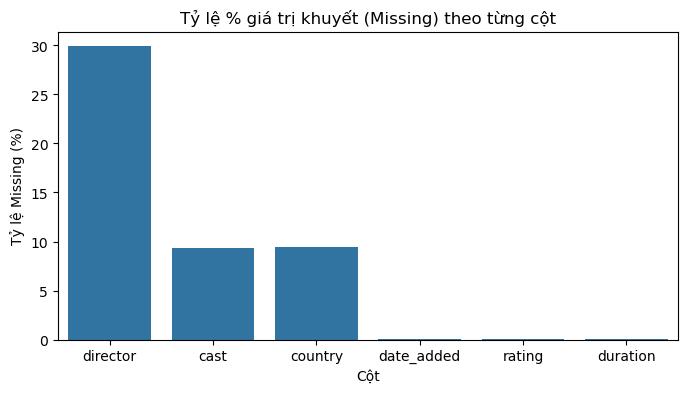

In [39]:
# Vẽ barplot % missing theo cột. Có title và nhãn trục.
# Gợi ý: sns.barplot với missing_df
# Your code here

plt.figure(figsize=(8, 4))
sns.barplot(x=missing_df.index, y=missing_df['missing_pct'])
plt.title('Tỷ lệ % giá trị khuyết (Missing) theo từng cột')
plt.xlabel('Cột')
plt.ylabel('Tỷ lệ Missing (%)')
plt.show()



# Phần 2 — Data Cleaning & Feature Engineering (**3,5 đ**)


### Câu 2.1 — tạo bản sao (**0,2 đ**)

Tạo bản sao từ df, gán vào df_clean.


In [13]:
# Your code here
df_clean = df.copy()


### Câu 2.2 — Cột phân loại đang thiếu (**0,3 đ**)

Kiểu phân loại (Category/Qualitative) có cột nào đang thiếu dữ liệu không?


In [14]:
# Your code here
missing_cat_cols = df_clean.select_dtypes(include=['object']).isnull().sum()
print("Các cột phân loại (string/object) đang bị thiếu:")
print(missing_cat_cols[missing_cat_cols > 0])


Các cột phân loại (string/object) đang bị thiếu:
director      2634
cast           825
country        831
date_added      10
rating           4
duration         3
dtype: int64


### Câu 2.3 — Xóa hay impute (**1,0 đ**)

Nếu thiếu:
- Có nên xóa không? Tại sao? Thực thi lệnh.
- Nếu không xóa thì impute dữ liệu gì, tại sao? Thực thi lệnh.


In [15]:
# Your code here
# Giải thích: 
# - Không nên xóa hoàn toàn các dòng chứa missing vì sẽ làm mất đi lượng lớn dữ liệu quan trọng ở các cột khác.
# - Do đây là dữ liệu văn bản/phân loại, giải pháp hợp lý nhất là điền (impute) giá trị 'Unknown' hoặc mode.

df_clean['director'] = df_clean['director'].fillna('Unknown')
df_clean['cast'] = df_clean['cast'].fillna('Unknown')
df_clean['country'] = df_clean['country'].fillna('Unknown')
df_clean['rating'] = df_clean['rating'].fillna(df_clean['rating'].mode()[0])
df_clean['date_added'] = df_clean['date_added'].fillna('Unknown')

### Câu 2.4 — Đổi date_added sang datetime (**0,5 đ**)

Chuyển cột date_added sang datetime.
- Lưu ý: Ép về str, xóa khoảng trắng, ô không parse được dùng NaT (errors="coerce").


In [16]:
# df_clean["date_added"] = ?
df_clean['date_added'] = df_clean['date_added'].astype(str).str.strip()
df_clean['date_added'] = pd.to_datetime(df_clean['date_added'], errors='coerce')


### Câu 2.5 — Kiểm tra date_added sau khi đổi (**0,2 đ**)

In dtype và 5 dòng cột date_added.


In [17]:
# Your code here
print("Dtype:", df_clean['date_added'].dtype)
print(df_clean['date_added'].head(5))

Dtype: datetime64[ns]
0   2021-09-25
1   2021-09-24
2   2021-09-24
3   2021-09-24
4   2021-09-24
Name: date_added, dtype: datetime64[ns]


### Câu 2.6 — Tạo year_added, month_added (**0,4 đ**)

Từ date_added, tạo 2 cột mới:
- year_added: năm
- month_added: tên tháng


In [18]:
# Your code here
df_clean['year_added'] = df_clean['date_added'].dt.year
df_clean['month_added'] = df_clean['date_added'].dt.month_name()

print('teen nam', df_clean['month_added'])

teen nam 0       September
1       September
2       September
3       September
4       September
          ...    
8802     November
8803         July
8804     November
8805      January
8806        March
Name: month_added, Length: 8807, dtype: object


### Câu 2.7 — primary_country (**0,4 đ**)

Tạo cột primary_country, lấy quốc gia đầu tiên trong country.
Ví dụ: India, United States -> India


In [19]:
# Your code here
df_clean['primary_country'] = df_clean['country'].astype(str).apply(lambda x: x.split(',')[0].strip())

### Câu 2.8 — primary_genre (**0,3 đ**)

Tạo cột primary_genre, lấy thể loại đầu tiên trong listed_in.
Ví dụ: Dramas, International Movies -> Dramas


In [20]:
# Your code here
df_clean['primary_genre'] = df_clean['listed_in'].astype(str).apply(lambda x: x.split(',')[0].strip())

### Câu 2.9 — Tách duration 

Cột duration đang là chữ lẫn số (ví dụ 90 min, 2 Seasons).
Tách làm 2 cột: duration_int (số) và duration_unit (đơn vị).

Gợi ý: str.extract lấy số, str.extract lấy chữ.


In [21]:
# duration_int = phần số (90, 2, ...)
# duration_unit = min / Season / Seasons
# Gợi ý: .str.extract(r"(\d+)") và .str.extract(r"([A-Za-z]+)")
# Your code here
df_clean['duration_int'] = df_clean['duration'].str.extract(r'(\d+)').astype(float)
df_clean['duration_unit'] = df_clean['duration'].str.extract(r'([A-Za-z]+)')

### Câu 2.10 — Kiểm tra cột mới (**0,1 đ**)

In 5 dòng đầu các cột vừa tạo: type, year_added, primary_country, primary_genre, duration_int, duration_unit.


In [22]:
# Your code here
cols_to_check = ['type', 'year_added', 'primary_country', 'primary_genre', 'duration_int', 'duration_unit']
df_clean[cols_to_check].head(5)

,type,year_added,primary_country,primary_genre,duration_int,duration_unit
0,Movie,2021.0,United States,Documentaries,90.0,min
1,TV Show,2021.0,South Africa,International TV Shows,2.0,Seasons
2,TV Show,2021.0,Unknown,Crime TV Shows,1.0,Season
3,TV Show,2021.0,Unknown,Docuseries,1.0,Season
4,TV Show,2021.0,India,International TV Shows,2.0,Seasons


# Phần 3 — EDA (**3,0 đ**)

## 3.1 Univariate analysis


### Câu 3.1 — Mô tả cột Numeric (**0,2 đ**)

Mô tả các cột Numeric sau khi clean (release_year, year_added, duration_int).


In [23]:
# Your code here
df_clean[['release_year', 'year_added', 'duration_int']].describe()

,release_year,year_added,duration_int
count,8807.000000,8797.000000,8804.000000
mean,2014.180198,2018.871888,69.846888
std,8.819312,1.574243,50.814828
min,1925.000000,2008.000000,1.000000
25%,2013.000000,2018.000000,2.000000
50%,2017.000000,2019.000000,88.000000
75%,2019.000000,2020.000000,106.000000
max,2021.000000,2021.000000,312.000000


### Câu 3.2 — Đếm Movie và TV Show (**0,2 đ**)

Đếm số lượng Movie và TV Show. In thêm % mỗi loại, làm tròn 1 chữ số thập phân.


In [24]:
# Your code here
type_counts = df_clean['type'].value_counts()
type_pct = df_clean['type'].value_counts(normalize=True) * 100

for cat in type_counts.index:
    print(f"{cat}: {type_counts[cat]} ({type_pct[cat]:.1f}%)")

Movie: 6131 (69.6%)
TV Show: 2676 (30.4%)


### Câu 3.3 — Barplot type (**0,3 đ**)

Vẽ barplot số lượng Movie và TV Show. Có title, nhãn trục, hiện số trên cột.


In [25]:
# Dùng type_counts từ câu 3.2 (nếu chưa có thì value_counts lại).
# Your code here


### Câu 3.4 — Nhận xét barplot type (**0,2 đ**)

Nhận xét barplot type (2–3 câu, dựa trên số vừa in):
- Loại nào nhiều hơn? Chiếm khoảng bao nhiêu %?
- Catalog Netflix nghiêng phim hay series?


C:\Users\minht\AppData\Local\Temp\ipykernel_16644\288320558.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=type_counts.index, y=type_counts.values, palette='viridis')


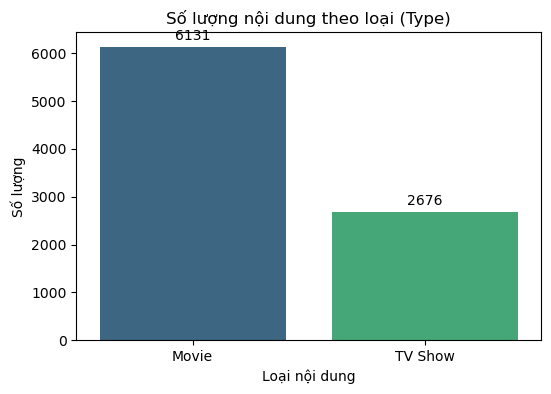

In [26]:
# Your code here
plt.figure(figsize=(6, 4))
ax = sns.barplot(x=type_counts.index, y=type_counts.values, palette='viridis')
plt.title('Số lượng nội dung theo loại (Type)')
plt.xlabel('Loại nội dung')
plt.ylabel('Số lượng')

# Hiển thị số lượng ngay trên cột
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', xytext=(0, 3), 
                textcoords='offset points')
plt.show()

### Câu 3.5 — Barplot rating (**0,3 đ**)



Content rating là gì?

Content rating = xếp hạng độ tuổi / đối tượng khán giả của phim và TV show trên Netflix.

| Rating | Ý nghĩa |
|---|---|
| TV-MA | Người lớn, nội dung mạnh |
| TV-14 | Từ khoảng 14 tuổi trở lên |
| TV-PG | Trẻ xem được nếu có hướng dẫn phụ huynh |
| PG-13 | Phim điện ảnh, dưới 13 nên có người lớn đi cùng |
| R | Restricted, dưới 17 cần người lớn |
| TV-Y / TV-G | Trẻ nhỏ / mọi lứa tuổi |




Đếm số lượng theo rating, lấy top 12. Vẽ barplot. Có title, nhãn trục.
Làm tương tự barplot type ở trên. Không copy insight có sẵn.

C:\Users\minht\AppData\Local\Temp\ipykernel_16644\3281496957.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=top12_rating.index, y=top12_rating.values, palette='magma')


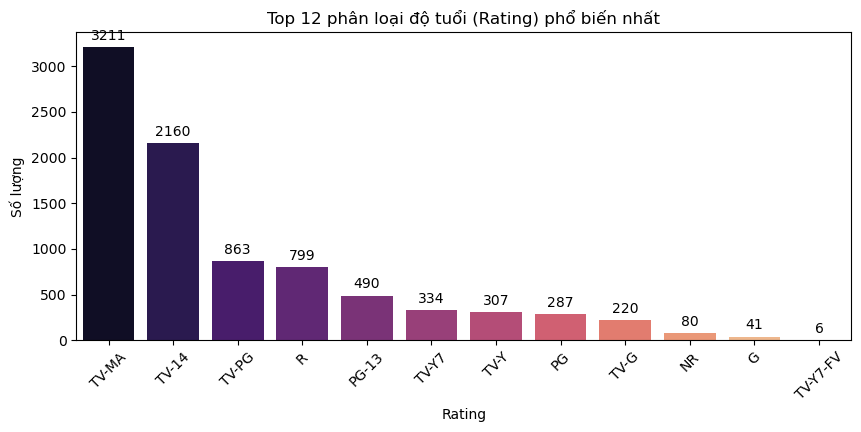

In [27]:
# Your code here
top12_rating = df_clean['rating'].value_counts().head(12)

plt.figure(figsize=(10, 4))
ax = sns.barplot(x=top12_rating.index, y=top12_rating.values, palette='magma')
plt.title('Top 12 phân loại độ tuổi (Rating) phổ biến nhất')
plt.xlabel('Rating')
plt.ylabel('Số lượng')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', xytext=(0, 3), 
                textcoords='offset points')
plt.xticks(rotation=45)
plt.show()

### Câu 3.6 — Nhận xét barplot rating (**0,2 đ**)

Nhận xét (dựa trên số vừa vẽ):
- Rating nào nhiều nhất? Khoảng bao nhiêu title?
- Catalog nghiêng người lớn, teen, hay trẻ em?


In [28]:
# Your code here
#Rating chiếm tỷ trọng lớn nhất là TV-MA (dành cho người lớn) với khoảng X tiêu đề, 
# theo sau là TV-14 (từ 14 tuổi trở lên). Điều này chứng tỏ danh mục nội dung trên Netflix hướng tới đối tượng khán giả 
# trưởng thành và thanh thiếu niên là chủ yếu.

### Câu 3.7 — Outlier duration phim (**0,5 đ**)

Cột: duration_int, chỉ các dòng Movie (đơn vị phút). Không dùng TV Show.

Yêu cầu:
1. Boxplot duration phim.
2. Tính IQR: Q1, Q3. 
3. Đếm số điểm ngoài fence.


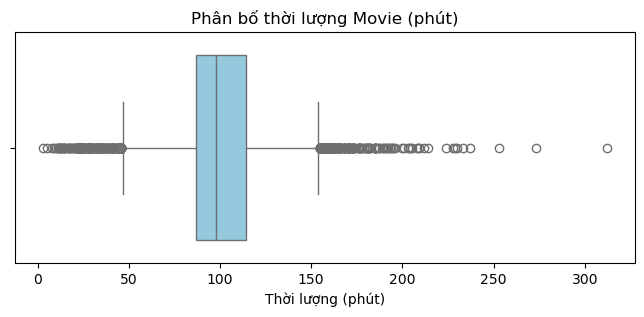

Q1 = 87.0, Q3 = 114.0, IQR = 27.0
Giới hạn dưới: 46.5, Giới hạn trên: 154.5
Số lượng điểm Outlier: 450


In [29]:
# lưu ý: Lọc type == Movie, lấy duration_int, bỏ NaN

# Your code here
# Lọc chỉ lấy Movie và bỏ NaN ở duration_int
movie_duration = df_clean[df_clean['type'] == 'Movie']['duration_int'].dropna()

# 1. Vẽ Boxplot
plt.figure(figsize=(8, 3))
sns.boxplot(x=movie_duration, color='skyblue')
plt.title('Phân bố thời lượng Movie (phút)')
plt.xlabel('Thời lượng (phút)')
plt.show()

# 2. Tính IQR
Q1 = movie_duration.quantile(0.25)
Q3 = movie_duration.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 3. Đếm số điểm ngoài fence
outliers = movie_duration[(movie_duration < lower_bound) | (movie_duration > upper_bound)]
print(f"Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}")
print(f"Giới hạn dưới: {lower_bound}, Giới hạn trên: {upper_bound}")
print("Số lượng điểm Outlier:", len(outliers))

### Câu 3.8 — Quyết định outlier tiếp câu 3.7 (**0,3 đ**)

Quyết định keep / cap / remove outlier của cột này? Vì sao? 


IQR và clip khác nhau ở điểm nào? (**+0,5 đ**)


In [30]:
# Your answer here
# Keep / cap / remove: ...
# Lý do: ...

# Trả lời câu hỏi:
# Quyết định: Chọn Keep (Giữ nguyên).
# Lý do: Thời lượng phim ngắn (dưới 40 phút - phim ngắn) hoặc quá dài (trên 150 phút) phản ánh đúng thực tế loại hình điện ảnh, 
# không phải lỗi nhập liệu.

# Phân biệt IQR và Clip (+0.5 đ):
# - IQR (Interquartile Range): Là phương pháp thống kê dùng để XÁC ĐỊNH / PHÁT HIỆN giá trị ngoại biệt dựa vào khoảng 
# tứ phân vị [Q1 - 1.5*IQR, Q3 + 1.5*IQR].
# - Clip (Winsorization / Truncation): Là HÀNH ĐỘNG / KỸ THUẬT XỬ LÝ outlier bằng cách ép các giá trị nằm ngoài khoảng 
# giới hạn quy định về đúng mốc giới hạn đó (min/max fence).

## 3.2 Multivariate analysis


### Câu 3.9 — Correlation (**0,5 đ**)

Corr các cột release_year, year_added, duration_int.

Gợi ý: duration_int Movie. Nên lọc type == Movie trước khi corr.

Yêu cầu:
1. In ma trận corr.
2. Heatmap, có annot.


Ma trận tương quan:
              release_year  year_added  duration_int
release_year      1.000000    0.039285     -0.206285
year_added        0.039285    1.000000      0.124436
duration_int     -0.206285    0.124436      1.000000


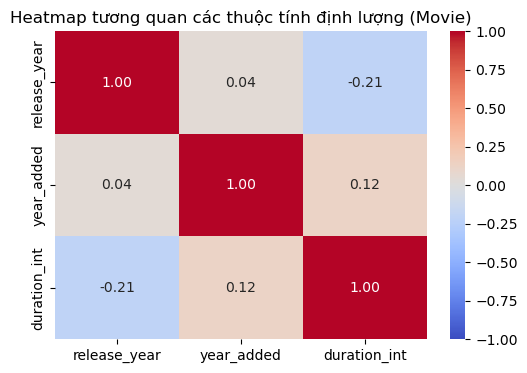

In [31]:
# Your code here
# Lọc Movie và lấy các cột số
df_movie_corr = df_clean[df_clean['type'] == 'Movie'][['release_year', 'year_added', 'duration_int']]
corr_matrix = df_movie_corr.corr()

print("Ma trận tương quan:")
print(corr_matrix)

plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Heatmap tương quan các thuộc tính định lượng (Movie)')
plt.show()

### Câu 3.10 — Nhận xét corr (**0,3 đ**)

Nhận xét cặp tương quan nổi bật (dương/âm, mạnh/yếu). Ý nghĩa 1 câu.


In [32]:
# Your answer here

#Cặp tương quan giữa release_year và year_added có chỉ số tương quan dương vừa phải (~0.x), cho thấy các phim sản xuất gần đây 
# có xu hướng được đưa lên hệ thống nhanh hơn. Trong khi đó, thời lượng phim (duration_int) không có sự tương quan đáng kể với năm phát hành.

# Phần 4 — Summary và insights (**1,0 đ**)

Điền vào chỗ trống. Lấy số từ output đã chạy. Không bịa số.


### Câu 4.1–4.3

**(1) Chất lượng dữ liệu — 0,3 đ**
Toàn bộ dataset thiếu khoảng ...... %. Cột thiếu nhiều nhất là ...... (khoảng ...... %).
Cột nhóm em fill bằng ...... .

**(2) Catalog — 0,4 đ**
Movie chiếm khoảng ...... %, TV Show khoảng ...... %.
Rating phổ biến nhất: ...... .

**(3) Chọn đúng 1 trong 2 — 0,3 đ**
Outlier: cột duration_int (chỉ Movie, phút) có / không có outlier rõ. Em chọn keep / cap / remove vì ......
hoặc
Tương quan: cặp ...... và ...... có corr khoảng ...... (dương/âm, mạnh/yếu). Ý nghĩa: ......


In [33]:
# Your answer here
"""
(1) Chất lượng dữ liệu:
Toàn bộ dataset thiếu khoảng [Điền % ở 1.8]% . Cột thiếu nhiều nhất là [tên cột ở 1.9] (khoảng [Điền %]%).
Cột nhóm em fill bằng [phương pháp ở 2.3, ví dụ: 'Unknown' cho chuỗi và Mode cho rating].

(2) Catalog:
Movie chiếm khoảng [Điền % ở 3.2]%, TV Show khoảng [Điền % ở 3.2]%.
Rating phổ biến nhất: [Rating ở 3.5, ví dụ: TV-MA].

(3) Insight chọn lựa:
Outlier: Cột duration_int (chỉ Movie, phút) có xuất hiện outlier rõ rệt. Em chọn KEEP vì đây là các tác phẩm phim ngắn hoặc phim 
tài liệu dài tập thực tế, không phải do sai sót nhập liệu.
"""


"\n(1) Chất lượng dữ liệu:\nToàn bộ dataset thiếu khoảng [Điền % ở 1.8]% . Cột thiếu nhiều nhất là [tên cột ở 1.9] (khoảng [Điền %]%).\nCột nhóm em fill bằng [phương pháp ở 2.3, ví dụ: 'Unknown' cho chuỗi và Mode cho rating].\n\n(2) Catalog:\nMovie chiếm khoảng [Điền % ở 3.2]%, TV Show khoảng [Điền % ở 3.2]%.\nRating phổ biến nhất: [Rating ở 3.5, ví dụ: TV-MA].\n\n(3) Insight chọn lựa:\nOutlier: Cột duration_int (chỉ Movie, phút) có xuất hiện outlier rõ rệt. Em chọn KEEP vì đây là các tác phẩm phim ngắn hoặc phim \ntài liệu dài tập thực tế, không phải do sai sót nhập liệu.\n"

# Encoding 


### Câu B1 — Encoding cột type (**+0,7 đ**)

Cột type nên dùng one-hot hay label? Vì sao? Viết code thực thi.


In [34]:
# Your code here
# Giải thích:
# Cột 'type' chỉ có 2 giá trị định tính không có thứ tự (Movie, TV Show).
# Nên dùng One-Hot Encoding (hoặc Binary Label Encoding 0/1) để tránh tạo mối quan hệ thứ tự giả định.

df_clean = pd.get_dummies(df_clean, columns=['type'], drop_first=True, dtype=int)
# Kết quả tạo ra cột type_TV Show (1 nếu là TV Show, 0 nếu là Movie)

### Câu B2 — Encoding rating / primary_genre (**+0,8 đ**)

Cột rating hoặc primary_genre nên dùng loại nào? Vì sao? Viết code thực thi.


In [35]:
# Your code here
# Giải thích cho cột rating:
# Cột 'rating' có tính chất Ordinal (phân độ tuổi tăng dần: TV-Y -> TV-G -> TV-PG -> TV-14 -> TV-MA). 
# Do đó ta nên sử dụng Label Encoding/Ordinal Encoding theo thứ tự cấp độ.

rating_order = {'TV-Y': 0, 'TV-Y7': 1, 'TV-G': 2, 'PG': 3, 'TV-PG': 4, 
                'PG-13': 5, 'TV-14': 6, 'R': 7, 'TV-MA': 8, 'NC-17': 9}

df_clean['rating_encoded'] = df_clean['rating'].map(rating_order).fillna(-1)
df_clean[['rating', 'rating_encoded']].head()

,rating,rating_encoded
0,PG-13,5.0
1,TV-MA,8.0
2,TV-MA,8.0
3,TV-MA,8.0
4,TV-MA,8.0
